In [2]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [3]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import shap
import matplotlib.pyplot as plt

ARTIFACTS = Path("../artifacts")
RESULTS = Path("../results")

df = pd.read_csv(ARTIFACTS / "clean_data.csv")
TARGET = "CO2 uptake (mmol/g)"
FEATURES = [c for c in df.columns if c not in ["row_id", TARGET, "split"]]

final_models = joblib.load(ARTIFACTS / "final_models.joblib")
with open(ARTIFACTS / "ensemble_weights.json") as f:
    weights = pd.Series(json.load(f))

imputer = final_models["CatBoost"].named_steps["impute"]
X_all = pd.DataFrame(imputer.transform(df[FEATURES]), columns=FEATURES)
print(X_all.shape)

(526, 10)


In [4]:
shap_parts = {}
for name, pipe in final_models.items():
    explainer = shap.TreeExplainer(pipe.named_steps["model"])
    shap_parts[name] = explainer.shap_values(X_all)
    print(name, "done")

shap_ens = sum(weights[n] * shap_parts[n] for n in weights.index)

Random Forest done
Extra Trees done
Gradient Boosting done
XGBoost done
LightGBM done
CatBoost done


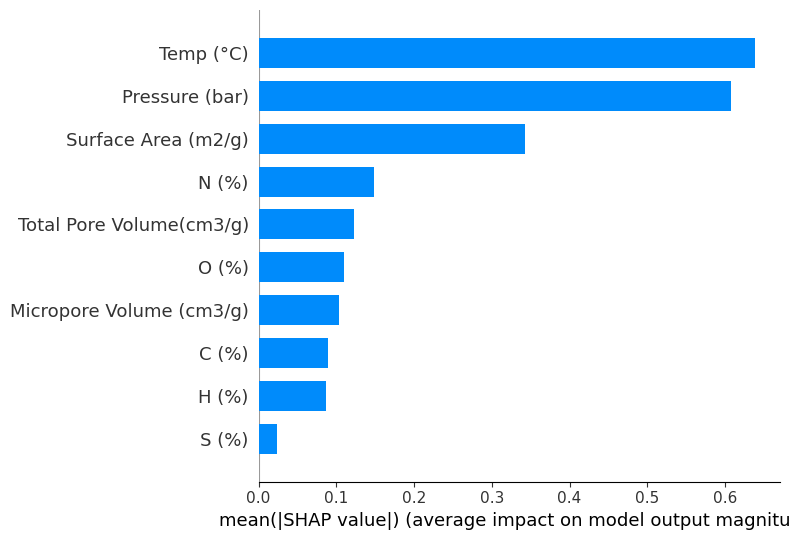

Temp (°C)                   0.639
Pressure (bar)              0.607
Surface Area (m2/g)         0.343
N (%)                       0.149
Total Pore Volume(cm3/g)    0.123
O (%)                       0.109
Micropore Volume (cm3/g)    0.104
C (%)                       0.089
H (%)                       0.087
S (%)                       0.023
dtype: float64

In [5]:
importance = pd.Series(np.abs(shap_ens).mean(axis=0), index=FEATURES).sort_values(ascending=False)

shap.summary_plot(shap_ens, X_all, plot_type="bar", show=False)
plt.savefig(RESULTS / "08_shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()
importance.round(3)

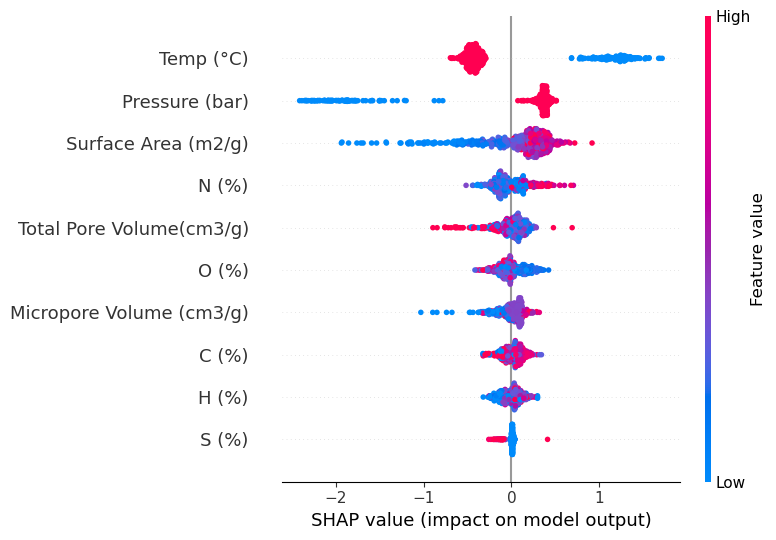

In [6]:
shap.summary_plot(shap_ens, X_all, show=False)
plt.savefig(RESULTS / "08_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

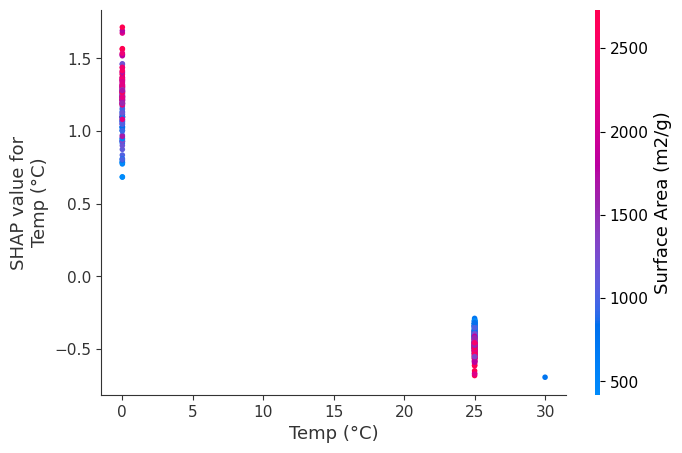

In [7]:
top = importance.index[0]
shap.dependence_plot(top, shap_ens, X_all, show=False)
plt.savefig(RESULTS / "08_shap_dependence_top.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
importance.round(4).to_csv(RESULTS / "08_shap_importance.csv")
print("saved")

saved
